# Advanced FM

Beyond two operators: composite modulators, feedback FM, and the special-purpose generators `asymmetric_fm` and `ssb_am`.

Source: [FM documentation](https://ccrma.stanford.edu/software/snd/snd/fm.html)

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd

import pysndlib.clm as clm

SR = 44100

def spectrum(x, n=4096):
    rl = np.copy(x[:n].astype(float)); im = np.zeros(n)
    clm.mus_fft(rl, im, n, 1)
    clm.mus_rectangular2polar(rl, im)
    return np.abs(rl[:n//2])

def show(x, title, fmax=6000):
    f = np.arange(2048) * SR / 4096
    plt.plot(f, spectrum(x), lw=0.8); plt.xlim(0, fmax)
    plt.title(title); plt.show()

## Composite modulators

Two modulators in parallel give a spectrum neither alone would produce (summing their outputs into the carrier's input):

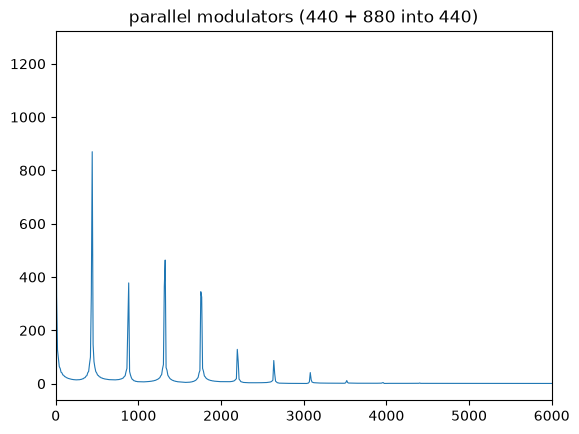

In [2]:
with clm.Sound('parallel.wav', channels=1, srate=SR):
    car = clm.make_oscil(440.0)
    m1 = clm.make_oscil(440.0)
    m2 = clm.make_oscil(880.0)
    amp = clm.make_env([0, 0, 5, 1, 95, 1, 100, 0], duration=1.0)
    for i in range(SR):
        fm = 2.0 * clm.oscil(m1) + 1.5 * clm.oscil(m2)   # parallel modulators
        clm.outa(i, clm.env(amp) * clm.oscil(car, clm.hz2radians(440.0) * fm))

par, _ = clm.file2ndarray('parallel.wav')
show(par[0], 'parallel modulators (440 + 880 into 440)')

In [3]:
ipd.Audio('parallel.wav', rate=SR)

A serial (cascade) arrangement modulates the modulator itself -- spectra get much denser:

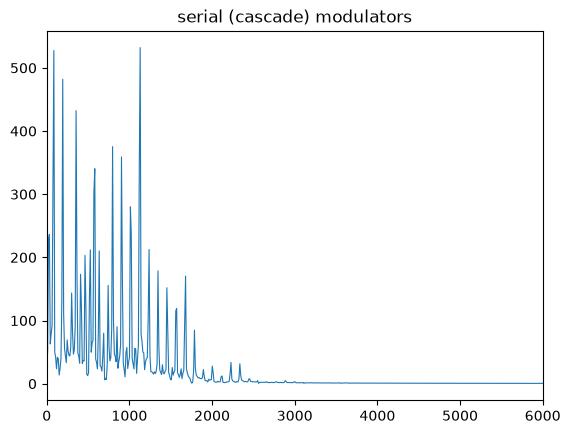

In [4]:
with clm.Sound('serial.wav', channels=1, srate=SR):
    car = clm.make_oscil(440.0)
    m1 = clm.make_oscil(440.0)
    m2 = clm.make_oscil(110.0)
    amp = clm.make_env([0, 0, 5, 1, 95, 1, 100, 0], duration=1.0)
    for i in range(SR):
        fm = clm.oscil(m1, clm.oscil(m2) * clm.hz2radians(110.0) * 2.0)  # m2 modulates m1
        clm.outa(i, clm.env(amp) * clm.oscil(car, fm * clm.hz2radians(440.0) * 2.0))

ser, _ = clm.file2ndarray('serial.wav')
show(ser[0], 'serial (cascade) modulators')

In [5]:
ipd.Audio('serial.wav', rate=SR)

## Feedback FM

Feedback FM (Tomisawa, via the [FM documentation](https://ccrma.stanford.edu/software/snd/snd/fm.html))
is a fixed-point iteration: `y = x + B*sin(y)` where `x` is the carrier's pure phase ramp
(`hz2radians` per sample) and `B` is a dimensionless index valid 0 to 1.5. The spectrum
is `(2/nB) J_n(nB)` -- harmonics fall off as 1/n, i.e., a much broader, flatter, sawtooth-like
spectrum than ordinary FM. Note the phase ramp must stay pure (a bare `oscil` fed back into
its own fm input *accumulates* the feedback and collapses to silence); Tomisawa's form
recomputes the feedback fresh against the ramp each sample:

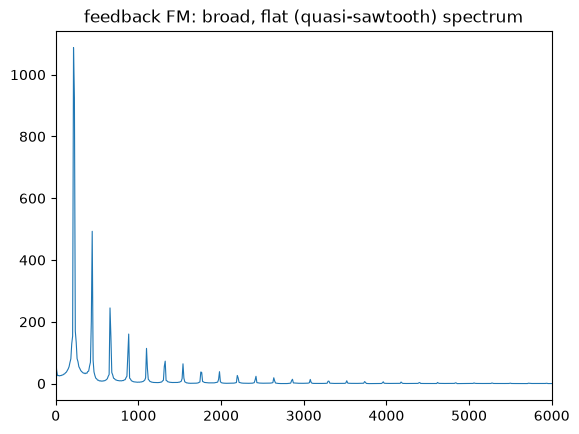

In [60]:
import math

with clm.Sound('feedback.wav', channels=1, srate=SR):
    x = 0.0
    y = 0.0
    x_inc = clm.hz2radians(220.0)       # carrier phase advance per sample
    amp = clm.make_env([0, 0, 5, 1, 95, 1, 100, 0], duration=1.0)
    index = 0.9                         # Tomisawa: 0 < B < 1.5
    for i in range(SR):
        y = x + index * math.sin(y)     # feedback recomputed against the pure ramp
        x += x_inc
        clm.outa(i, clm.env(amp) * math.sin(y))

fbk, _ = clm.file2ndarray('feedback.wav')
show(fbk[0], 'feedback FM: broad, flat (quasi-sawtooth) spectrum')

In [7]:
ipd.Audio('feedback.wav', rate=SR)

## asymmetric_fm

`asymmetric_fm` shapes the spectrum asymmetrically around the carrier (the classic "single-sideband-ish" FM sound):

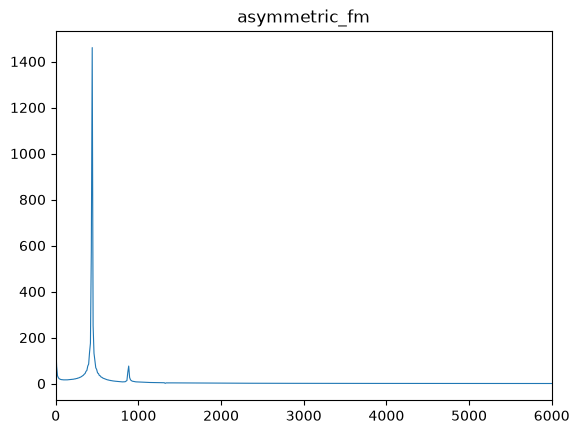

In [61]:
with clm.Sound('afm.wav', channels=1, srate=SR):
    a = clm.make_asymmetric_fm(440.0, r=1.0, ratio=1.0)
    amp = clm.make_env([0, 0, 5, 1, 95, 1, 100, 0], duration=1.0)
    idx = clm.make_env([0, 0, 100, 2], duration=1.0)     # the index is a per-sample input
    for i in range(SR):
        clm.outa(i, clm.env(amp) * clm.asymmetric_fm(a, clm.env(idx)))

afm, _ = clm.file2ndarray('afm.wav')
show(afm[0], 'asymmetric_fm')

In [9]:
ipd.Audio('afm.wav', rate=SR)

## Summary

- Parallel/serial modulator arrangements multiply spectral possibilities
- Feedback FM (Tomisawa: y = x + B*sin(y), index 0-1.5) gives a broad, flat,
  sawtooth-like spectrum; the phase ramp must stay pure -- a bare oscil fed back
  into its own fm input collapses to silence


Next: [other waveform generators](09_Waveforms.ipynb)